<a href="https://colab.research.google.com/github/kavyasri378/SAT-2-FOOD-DELIVERY-INSIGHTS-/blob/main/ROUND_2_EDA_AND_FEATURE_ENGINEERING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Install & Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load Datasets

In [ ]:
# Load all 5 CSV files
orders_df = pd.read_csv('orders.csv')
delivery_df = pd.read_csv('delivery.csv')
riders_df = pd.read_csv('riders.csv')
routes_df = pd.read_csv('routes.csv')
weather_df = pd.read_csv('weather.csv')

print("Datasets loaded successfully!")
print(f"Orders shape: {orders_df.shape}")
print(f"Delivery shape: {delivery_df.shape}")

Datasets loaded successfully!
Orders shape: (2226, 7)
Delivery shape: (2200, 5)


# Data Quality Check & Cleaning

In [ ]:
# 1. Check and remove duplicate order IDs in orders dataset
print(f"Duplicate orders before cleaning: {orders_df['order_id'].duplicated().sum()}")
orders_df = orders_df.drop_duplicates(subset=['order_id'], keep='first')

# 2. Standardize categorical zone names (fixing casing inconsistencies like 'east zone' vs 'East Zone')
orders_df['customer_zone'] = orders_df['customer_zone'].str.title().str.strip()
routes_df['zone'] = routes_df['zone'].str.title().str.strip()
weather_df['zone'] = weather_df['zone'].str.title().str.strip()

# 3. Handle missing values in timestamps
delivery_df['pickup_time'] = pd.to_datetime(delivery_df['pickup_time'])
delivery_df['delivered_time'] = pd.to_datetime(delivery_df['delivered_time'])
orders_df['order_time'] = pd.to_datetime(orders_df['order_time'])

# Drop rows where critical timestamps are missing
delivery_df = delivery_df.dropna(subset=['pickup_time', 'delivered_time'])

print("Data cleaning completed successfully.")

Duplicate orders before cleaning: 26
Data cleaning completed successfully.


# Data Integration (Merging Datasets)

In [ ]:
# Merge orders with delivery data
master_df = orders_df.merge(delivery_df, on='order_id', how='inner')

# Merge with riders data
master_df = master_df.merge(riders_df, on='rider_id', how='left')

# Merge with routes data
master_df = master_df.merge(routes_df, on='route_id', how='left', suffixes=('', '_route'))
# Clean up duplicate zone column if needed
if 'zone_route' in master_df.columns:
    master_df = master_df.drop(columns=['zone_route'])

# Merge with weather data based on date and zone
weather_df['weather_date'] = pd.to_datetime(weather_df['weather_date']).dt.date
master_df['order_date'] = master_df['order_time'].dt.date

master_df = master_df.merge(
    weather_df,
    left_on=['order_date', 'customer_zone'],
    right_on=['weather_date', 'zone'],
    how='left'
)

print(f"Master dataset shape after merging: {master_df.shape}")

Master dataset shape after merging: (2145, 23)


# Feature Engineering

In [ ]:
# 1. Calculate preparation time (Order to Pickup in minutes)
master_df['prep_time_mins'] = (master_df['pickup_time'] - master_df['order_time']).dt.total_seconds() / 60

# 2. Calculate transit time (Pickup to Delivery in minutes)
master_df['transit_time_mins'] = (master_df['delivered_time'] - master_df['pickup_time']).dt.total_seconds() / 60

# 3. Calculate total delivery time (Order to Delivery in minutes)
master_df['total_delivery_time_mins'] = (master_df['delivered_time'] - master_df['order_time']).dt.total_seconds() / 60

# 4. Extract time-based features
master_df['order_hour'] = master_df['order_time'].dt.hour
master_df['order_day_of_week'] = master_df['order_time'].dt.day_name()

# 5. Define congestion / time periods
def get_time_period(hour):
    if 6 <= hour < 11:
        return 'Morning'
    elif 11 <= hour < 16:
        return 'Afternoon'
    elif 16 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

master_df['time_period'] = master_df['order_hour'].apply(get_time_period)

print("Feature engineering completed.")
print(master_df[['order_id', 'prep_time_mins', 'transit_time_mins', 'total_delivery_time_mins', 'time_period']].head())

Feature engineering completed.
  order_id  prep_time_mins  transit_time_mins  total_delivery_time_mins  \
0  O000001             8.0               15.0                      23.0   
1  O000002            10.0               35.0                      45.0   
2  O000003            24.0               21.0                      45.0   
3  O000004            12.0               35.0                      47.0   
4  O000005            19.0               33.0                      52.0   

  time_period  
0     Morning  
1     Morning  
2       Night  
3   Afternoon  
4     Morning  


# Exploratory Data Analysis & Answering Business Questions

Average Delivery Time by Zone:
  customer_zone  total_delivery_time_mins
0       Central                 38.063927
1     East Zone                 40.099237
2    North Zone                 41.652381
3    South Zone                 41.088235
4     West Zone                 36.002174


/tmp/ipykernel_2775/3007113188.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=zone_delivery, x='customer_zone', y='total_delivery_time_mins', palette='Blues_d')


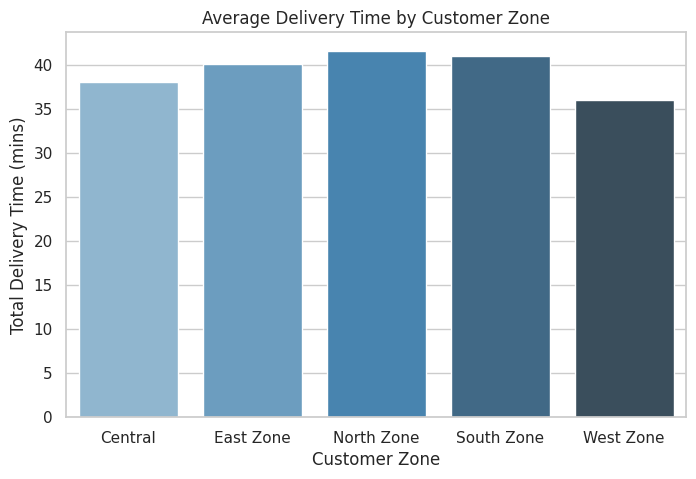

In [ ]:
# --- Question 1: Which zones have longer delivery times? ---
zone_delivery = master_df.groupby('customer_zone')['total_delivery_time_mins'].mean().reset_index()
print("Average Delivery Time by Zone:")
print(zone_delivery)

plt.figure(figsize=(8, 5))
sns.barplot(data=zone_delivery, x='customer_zone', y='total_delivery_time_mins', palette='Blues_d')
plt.title('Average Delivery Time by Customer Zone')
plt.ylabel('Total Delivery Time (mins)')
plt.xlabel('Customer Zone')
plt.show()


Average Delivery Time by Traffic Level:
  traffic_level  total_delivery_time_mins
0          High                 45.420732
1           Low                 34.208211
2        Medium                 39.759788


/tmp/ipykernel_2775/4132207060.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=master_df, x='traffic_level', y='total_delivery_time_mins', palette='Set2')


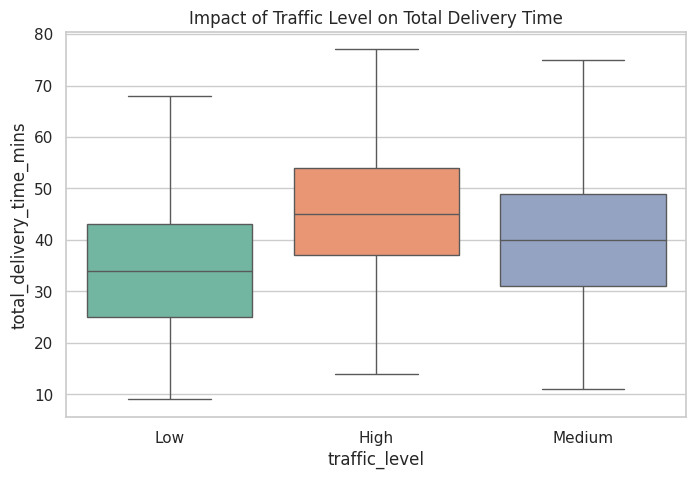

In [ ]:
# --- Question 2: How does traffic affect delivery? ---
traffic_delivery = master_df.groupby('traffic_level')['total_delivery_time_mins'].mean().reset_index()
print("\nAverage Delivery Time by Traffic Level:")
print(traffic_delivery)

plt.figure(figsize=(8, 5))
sns.boxplot(data=master_df, x='traffic_level', y='total_delivery_time_mins', palette='Set2')
plt.title('Impact of Traffic Level on Total Delivery Time')
plt.show()

In [ ]:
# --- Question 3: Does rain increase delay? ---
if 'rain_mm' in master_df.columns:
    master_df['is_raining'] = master_df['rain_mm'] > 0.0
    rain_delivery = master_df.groupby('is_raining')['total_delivery_time_mins'].mean().reset_index()
    print("\nAverage Delivery Time by Rain Status:")
    print(rain_delivery)


Average Delivery Time by Rain Status:
   is_raining  total_delivery_time_mins
0       False                 38.946593
1        True                 39.404822


In [ ]:
# --- Question 4: Which restaurants have longer pickup times? ---
rest_pickup = master_df.groupby('restaurant_id')['prep_time_mins'].mean().reset_index().sort_values(by='prep_time_mins', ascending=False)
print("\nTop 5 Restaurants with Longest Pickup Times:")
print(rest_pickup.head())


Top 5 Restaurants with Longest Pickup Times:
   restaurant_id  prep_time_mins
14          R015       12.805970
17          R018       12.560440
6           R007       12.430000
3           R004       12.417582
12          R013       12.402439


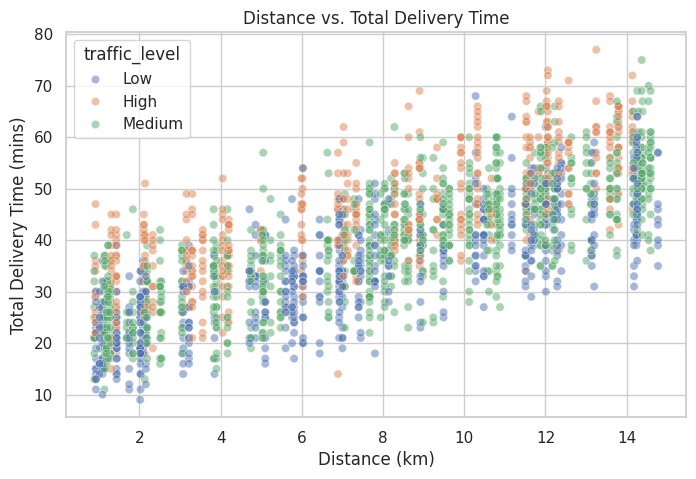

In [ ]:
# --- Question 5: How does distance relate to delivery time? ---
plt.figure(figsize=(8, 5))
sns.scatterplot(data=master_df, x='distance_km', y='total_delivery_time_mins', alpha=0.5, hue='traffic_level')
plt.title('Distance vs. Total Delivery Time')
plt.xlabel('Distance (km)')
plt.ylabel('Total Delivery Time (mins)')
plt.show()

In [ ]:
# --- Question 6: Which time periods are most congested? ---
time_congestion = master_df['time_period'].value_counts().reset_index()
time_congestion.columns = ['time_period', 'order_count']
print("\nOrder Volume by Time Period (Congestion):")
print(time_congestion)


Order Volume by Time Period (Congestion):
  time_period  order_count
0     Evening          694
1   Afternoon          637
2     Morning          537
3       Night          277


# Categorical Encoding & Feature Selection (Round 2 Requirement)

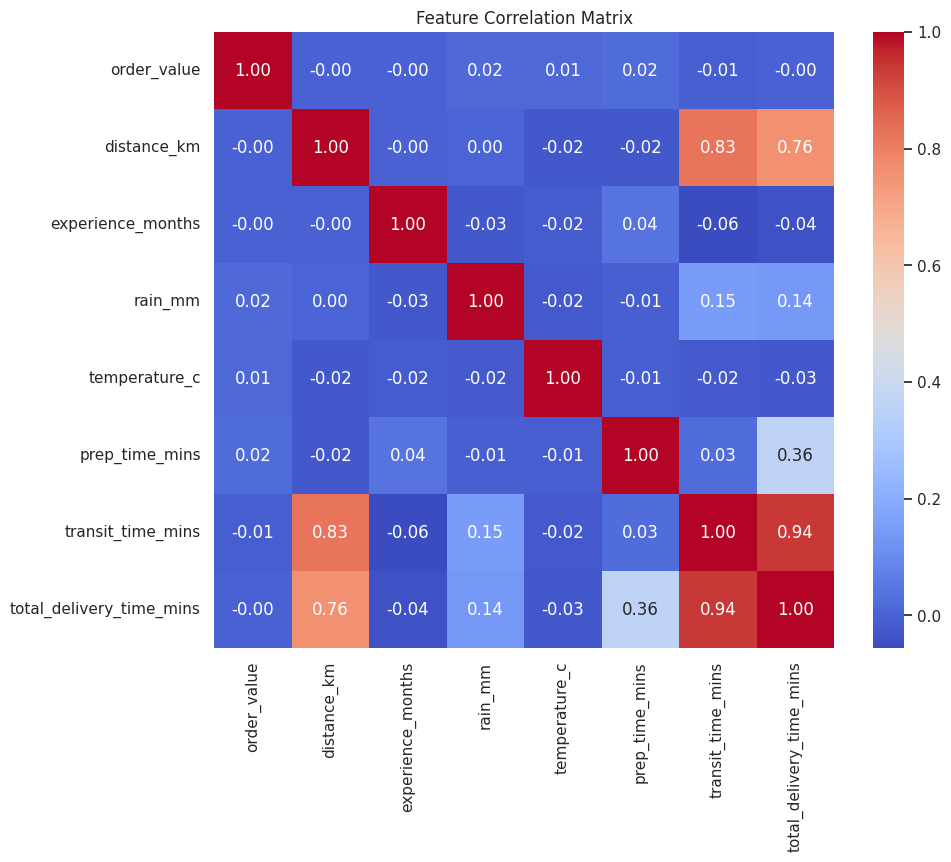

In [ ]:
from sklearn.preprocessing import LabelEncoder
encoded_df = master_df.copy()
cat_cols = ['customer_zone', 'traffic_level', 'shift', 'time_period']
le = LabelEncoder()

for col in cat_cols:
    if col in encoded_df.columns:
        encoded_df[col] = le.fit_transform(encoded_df[col].astype(str))

# Feature Selection / Correlation Matrix
numeric_cols = ['order_value', 'distance_km', 'experience_months', 'rain_mm',
                'temperature_c', 'prep_time_mins', 'transit_time_mins', 'total_delivery_time_mins']
corr_matrix = encoded_df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()